 Кластеризация и снижение размерности (10 баллов + 5 бонус)

# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличе работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

In [2]:
import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt

import plotly.io as pio
import matplotlib_inline

sns.set(style="ticks", context="talk")
plt.style.use("dark_background")
pio.templates.default = pio.templates.merge_templates("plotly_dark", "presentation")
matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'svg')

pd.set_option('display.max_columns', None)

# Кластеризация иерархии животных



Будем использовать данные, описывающие признаки различных животных https://www.kaggle.com/datasets/uciml/zoo-animal-classification/data

<font color='CornflowerBlue'>**Цель**</font> --- выявить кластера различных классов животных, а также построить их иерархию

In [3]:
! gdown 106wQ0gOlT8drsG0OeWBAM_s7CgEsUxVc
! gdown 1j9o40Aubng-Hoe9kaGwSIXD6s9z_7e8c

Downloading...
From: https://drive.google.com/uc?id=106wQ0gOlT8drsG0OeWBAM_s7CgEsUxVc
To: /content/zoo.csv
100% 4.37k/4.37k [00:00<00:00, 11.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1j9o40Aubng-Hoe9kaGwSIXD6s9z_7e8c
To: /content/class.csv
100% 963/963 [00:00<00:00, 3.40MB/s]


In [4]:
data = pd.read_csv("/content/zoo.csv")
classes = pd.read_csv("/content/class.csv")

Посмотрим на данные

In [5]:
data.head()

,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


In [6]:
classes.head(n=10)

,Class_Number,Number_Of_Animal_Species_In_Class,Class_Type,Animal_Names
0,1,41,Mammal,"aardvark, antelope, bear, boar, buffalo, calf,..."
1,2,20,Bird,"chicken, crow, dove, duck, flamingo, gull, haw..."
2,3,5,Reptile,"pitviper, seasnake, slowworm, tortoise, tuatara"
3,4,13,Fish,"bass, carp, catfish, chub, dogfish, haddock, h..."
4,5,4,Amphibian,"frog, frog, newt, toad"
5,6,8,Bug,"flea, gnat, honeybee, housefly, ladybird, moth..."
6,7,10,Invertebrate,"clam, crab, crayfish, lobster, octopus, scorpi..."


Всего <font color='CornflowerBlue'>**7 классов**</font> животных. Сначала мы посмотрим на кластеризацию, а затем будем сравнивать ее истиной разметкой

In [7]:
names = data["animal_name"]
data.drop("animal_name", axis=1, inplace=True)

y = data["class_type"]
data.drop("class_type", axis=1, inplace=True)

### **<font color='DarkOrange'> Задача 1. [0.5 балла]**</font>

#### <font color='plum'>**Исследование признаков**</font>

* Исследуйте признаки в данных `data`. Какого они типа (в классификации вещественный/категориальный/бинарный итд)?
* Отметьте выделяющиеся признаки и преобразуйте их в такой формат, как и большинство остальных признаков

In [8]:
print("Типы данных в датасете:")
print(data.dtypes)
print("\nСтатистика по признакам:")
print(data.describe())
print("\nУникальные значения по столбцам:")
for col in data.columns:
    print(f"{col}: {data[col].unique()}")
#data = # Your code here

Типы данных в датасете:
hair        int64
feathers    int64
eggs        int64
milk        int64
airborne    int64
aquatic     int64
predator    int64
toothed     int64
backbone    int64
breathes    int64
venomous    int64
fins        int64
legs        int64
tail        int64
domestic    int64
catsize     int64
dtype: object

Статистика по признакам:
             hair    feathers        eggs        milk    airborne     aquatic  \
count  101.000000  101.000000  101.000000  101.000000  101.000000  101.000000   
mean     0.425743    0.198020    0.584158    0.405941    0.237624    0.356436   
std      0.496921    0.400495    0.495325    0.493522    0.427750    0.481335   
min      0.000000    0.000000    0.000000    0.000000    0.000000    0.000000   
25%      0.000000    0.000000    0.000000    0.000000    0.000000    0.000000   
50%      0.000000    0.000000    1.000000    0.000000    0.000000    0.000000   
75%      1.000000    0.000000    1.000000    1.000000    0.000000    1.000000   


### **<font color='DarkOrange'> Задача 2. [0.5 балла]**</font>
#### <font color='plum'>**Масштабирование**</font>

Мы хотим применить алгоритм кластеризации для выявления похожих кластеров. Нужно ли в данном случае (на преобразованных выше данных) приводить признаки в одному масштабу? Почему?

<font color='MediumOrchid'>**Ваши выводы тут:**</font>
Масштабирование не требуется, потому что:
1.Все признаки бинарные (0/1) кроме legs
2.Признак legs имеет значения в диапазоне 0-8, что сопоставимо с остальными признаками
3.Для K-means с бинарными данными масштабирование не критично
4.Евклидово расстояние будет работать корректно на таких данных

------------

Далее будем оценивать качество нашей кластеризации как по метрикам, так и по визуальной оценке. Для этого приведем вспомогательную функцию. Если хотите что-то в ней улучшить/поменять - это можно сделать

In [9]:
from functools import partial

def show_slider(X_reduced, cluster_colors, iteration, title, prefix, suffix=""):
    """
    X_reduced: 2d np.array or pd.DataFrame, исходные данные, у которых снизили размерность
    по признакам до 2 или 3 фичей

    cluster_colors: list[iterable] - список раскрасок (кластеров), соответствующих
    каждому перебранному параметру K из iteration. Каждый элемент этого списка это фактически
    predict алгоритма кластеризации

    iteration: list[int] - сетка перебора параметра K

    title: str - название графика

    prefix: str - префикс названия слайдера

    suffix: str - суффикт названия слайдера

    """

    fig = go.Figure()

    method_2d = partial(px.scatter, x=0, y=1, color='cluster')
    method_3d = partial(px.scatter_3d, x=0, y=1, z=2, color='cluster')

    method = method_2d if X_reduced.shape[1] == 2 else method_3d

    for y in cluster_colors:
        df = pd.DataFrame(X_reduced)
        df["cluster"] = y.astype(int)
        fig.add_traces(list(method(data_frame=df).select_traces()))

    for n in range(1, len(fig.data)):
        fig.data[n].visible = False
    fig.data[0].visible = True

    steps = []
    for i in range(len(fig.data)):
        step = dict(
            method='update',
            args=[
                {'visible': [False] * len(fig.data)},
                {'color_continuous_scale': [px.colors.sequential.Plasma] * len(fig.data)},
                {'title.text': [title] * len(fig.data)}
            ],
            label=str(iteration[i]),
        )
        step['args'][0]['visible'][i] = True
        steps.append(step)

    sliders = [dict(
        active=0,
        steps=steps,
        currentvalue={"prefix": prefix, "suffix": suffix},
    )]

    fig.update_yaxes(autorange='reversed', scaleanchor='x', constrain='domain')
    fig.update_xaxes(constrain='domain')

    fig.layout.sliders = sliders
    fig.layout.title = title

    fig.show()

### **<font color='DarkOrange'> Задача 3. [1 балл]**</font>

#### <font color='plum'>**K-means**</font>

* Обучите несколько вариантов `k-means` с разными `k`
    * На основе имеющихся данных, какую бы сетку для перебора `k` (количество кластеров) вы сделали бы и почему?


In [10]:
from sklearn.cluster import KMeans
import tqdm

# your code here

cluster_colors = []
K = list(range(5, 10))

for k in tqdm.tqdm(K):
    # your code here
    # cluster_colors.append(kmeans.predict(...)) - как заполнять cluster_colors
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(data)
    cluster_colors.append(kmeans.predict(data))

100%|██████████| 5/5 [00:00<00:00, 18.50it/s]


<font color='MediumOrchid'>**Ваши выводы тут:**</font>
Сетка k от 5 до 9 выбрана потому что:
Известно, что в данных 7 классов животных.
Нужно проверить значения вокруг 7.

---------

### **<font color='DarkOrange'> Задача 4. [2 балла]**</font>

#### <font color='plum'>**Понижение размерности**</font>

* Сгенерируйте 2 разных варианта понижения размерности (для 2d случая и 3d случая) для каждого из следующих алгоритмов:
    * <font color='CornflowerBlue'>**PCA**</font>
    * <font color='CornflowerBlue'>**TSNE**</font> (`perplexity` можно выбрать в районе 6-8)
    * <font color='CornflowerBlue'>**Isomap**</font> (`n_neighbors` можно выбрать в районе 20-30)

Итого у вас должно получиться <font color='CornflowerBlue'>**6 разных вариантов**</font> понижения размерности

In [11]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, Isomap

In [12]:
# your code here
reduced_data = {}

pca_2d = PCA(n_components=2, random_state=42)
pca_3d = PCA(n_components=3, random_state=42)
reduced_data['pca_2d'] = pca_2d.fit_transform(data)
reduced_data['pca_3d'] = pca_3d.fit_transform(data)

tsne_2d = TSNE(n_components=2, random_state=42, perplexity=7)
tsne_3d = TSNE(n_components=3, random_state=42, perplexity=7)
reduced_data['tsne_2d'] = tsne_2d.fit_transform(data)
reduced_data['tsne_3d'] = tsne_3d.fit_transform(data)

isomap_2d = Isomap(n_components=2, n_neighbors=25)
isomap_3d = Isomap(n_components=3, n_neighbors=25)
reduced_data['isomap_2d'] = isomap_2d.fit_transform(data)
reduced_data['isomap_3d'] = isomap_3d.fit_transform(data)

print("Пониженные размерности:")
for name, arr in reduced_data.items():
    print(f"{name}: {arr.shape}")

Пониженные размерности:
pca_2d: (101, 2)
pca_3d: (101, 3)
tsne_2d: (101, 2)
tsne_3d: (101, 3)
isomap_2d: (101, 2)
isomap_3d: (101, 3)


### **<font color='DarkOrange'> Задача 5. [2 балла]**</font>

#### <font color='plum'>**Поиск наилучшей кластеризации**</font>

* Найдите оптимальное число кластеров используя
    * **<font color='DarkOrange'>(0.75 б)**</font> <font color='CornflowerBlue'>**оценку визуально**</font> - посмотрите на все 6 вариантов понижения размерности со слайдером по разным `k`
        * **<font color='DarkOrange'>(0.25 б)**</font> Какие методы понижения размерности оказались хорошими для визуализации кластеров?
    * **<font color='DarkOrange'>(0.75 б)**</font> <font color='CornflowerBlue'>**silhouette_score**</font> - постройте график зависимости этой метрики от `k`


* **<font color='DarkOrange'>(0.25 б)**</font> Какое оптимальное число кластеров получается для обоих способов их поиска? Почему вы остановились именно на таких значениях?

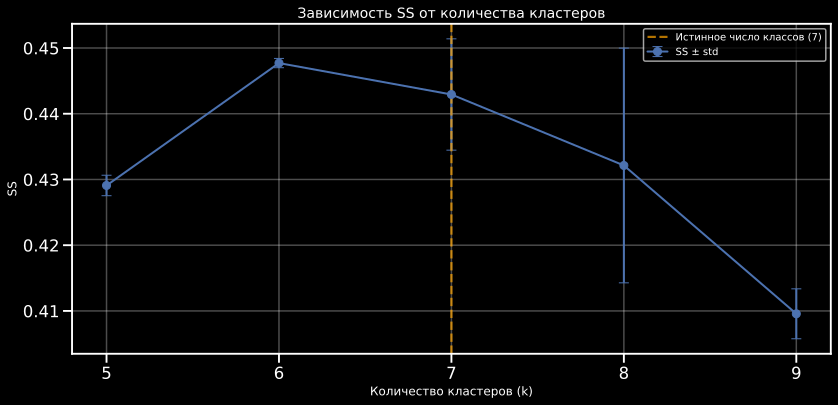

SS:
k= 5: 0.4291
k= 6: 0.4477
k= 7: 0.4429
k= 8: 0.4321
k= 9: 0.4096

Оптимальное k по SS: 6


In [13]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

methods_2d = ['pca_2d', 'tsne_2d', 'isomap_2d']
methods_3d = ['pca_3d', 'tsne_3d', 'isomap_3d']

for method in methods_2d:
    show_slider(reduced_data[method], cluster_colors, K,
                f"Clustering with {method.upper()}", "K=", "")
for method in methods_3d:
    show_slider(reduced_data[method], cluster_colors, K,
                f"Clustering with {method.upper()}", "K=", "")
from sklearn.metrics import silhouette_score

silhouette_scores = []
silhouette_std = []

for k in K:
    scores = []
    for seed in [42, 123, 456]:
        kmeans = KMeans(n_clusters=k, random_state=seed, n_init=10)
        labels = kmeans.fit_predict(data)
        score = silhouette_score(data, labels)
        scores.append(score)

    silhouette_scores.append(np.mean(scores))
    silhouette_std.append(np.std(scores))

plt.figure(figsize=(12, 6))
plt.errorbar(K, silhouette_scores, yerr=silhouette_std,
             fmt='bo-', capsize=5, linewidth=2, markersize=8, label='SS ± std')
plt.axvline(x=7, color='orange', linestyle='--', label='Истинное число классов (7)', alpha=0.7)
plt.xlabel('Количество кластеров (k)', fontsize=12)
plt.ylabel('SS', fontsize=12)
plt.title('Зависимость SS от количества кластеров', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.xticks(K)
plt.tight_layout()
plt.show()

print("SS:")
for k, score in zip(K, silhouette_scores):
    print(f"k={k:2d}: {score:.4f}")

optimal_k_silhouette = K[np.argmax(silhouette_scores)]
print(f"\nОптимальное k по SS: {optimal_k_silhouette}")

<font color='MediumOrchid'>**Ваши выводы тут:**</font>
isomap и pca оказались лучшими, но isomap все же по лучше
оптимальное кол во кластеров 6 в обоих тестах

### **<font color='MediumSeaGreen'> Бонус 1 [1 балл] </font>**

* Найдите также значение оптимального $k$ [методом локтя](https://www.geeksforgeeks.org/elbow-method-for-optimal-value-of-k-in-kmeans/), используя параметр [intertia_](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html#sklearn.cluster.KMeans) класса Kmeans. Не забудьте построить график зависимости `inertia_` от `k`. Изучите этот метод и инерцию при необходимости самостоятельно.
* Совпал ли ваш выбор с предыдущим заданием?

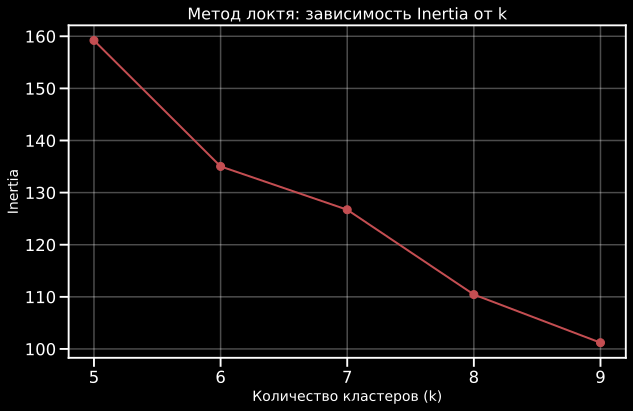

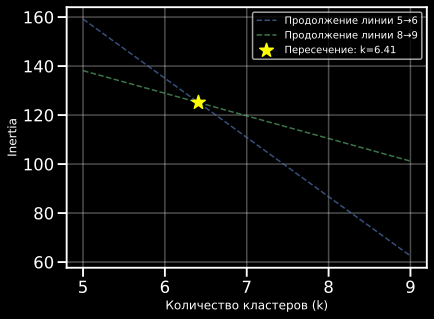

Оптимальное k по методу локтя: 6


In [14]:
# your code here
inertias = []
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(data)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(K, inertias, 'ro-', linewidth=2, markersize=8)
plt.xlabel('Количество кластеров (k)', fontsize=14)
plt.ylabel('Inertia', fontsize=14)
plt.title('Метод локтя: зависимость Inertia от k', fontsize=16)
plt.grid(True, alpha=0.3)
plt.xticks(K)
plt.show()



x1, x2 = 5, 6
y1, y2 = inertias[0], inertias[1]
slope_5_6 = (y2 - y1) / (x2 - x1)

x_extend_1 = np.array([5, 9])
y_extend_1 = y1 + slope_5_6 * (x_extend_1 - x1)
plt.plot(x_extend_1, y_extend_1, 'b--', linewidth=1.5, alpha=0.7,
         label='Продолжение линии 5→6')

x3, x4 = 8, 9
y3, y4 = inertias[3], inertias[4]
slope_8_9 = (y4 - y3) / (x4 - x3)

x_extend_2 = np.array([5, 9])
y_extend_2 = y3 + slope_8_9 * (x_extend_2 - x3)
plt.plot(x_extend_2, y_extend_2, 'g--', linewidth=1.5, alpha=0.7,
         label='Продолжение линии 8→9')

if slope_5_6 != slope_8_9:
    x_intersect = (y3 - slope_8_9 * x3 - y1 + slope_5_6 * x1) / (slope_5_6 - slope_8_9)
    y_intersect = y1 + slope_5_6 * (x_intersect - x1)
    plt.scatter([x_intersect], [y_intersect], color='yellow',
                s=200, zorder=5, marker='*', label=f'Пересечение: k={x_intersect:.2f}')

plt.xlabel('Количество кластеров (k)', fontsize=12)
plt.ylabel('Inertia', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.xticks(K)
plt.tight_layout()
plt.show()

optimal_k = round(x_intersect)
print(f'Оптимальное k по методу локтя: {optimal_k}')


<font color='MediumOrchid'>**Ваши выводы тут:**</font>
Оптимальное k по методу локтя: 6 как и в предыдущих случаях


### **<font color='MediumSeaGreen'> Бонус 2 [2 балла] </font>**

В самом датасете также присутствует и истинная разметка данных по классам.

* Изучите, как устроена внешняя [метрика качества BCubed](https://habr.com/ru/companies/yandex/articles/500742/), найдите реализацию или напишите ее сами.
* Выберите наилучший `k` исходя из имеющихся данных об эталонной разметке используя метрику `BCubed`
* Совпадает ли ваш выбор с предыдущими заданиями?

k=5: BCubed F1=0.8045 (Precision=0.7574, Recall=0.8578)
k=6: BCubed F1=0.7419 (Precision=0.7453, Recall=0.7385)
k=7: BCubed F1=0.7511 (Precision=0.7829, Recall=0.7218)
k=8: BCubed F1=0.8106 (Precision=0.8697, Recall=0.7589)
k=9: BCubed F1=0.7164 (Precision=0.8265, Recall=0.6321)

Оптимальное k по BCubed: 8


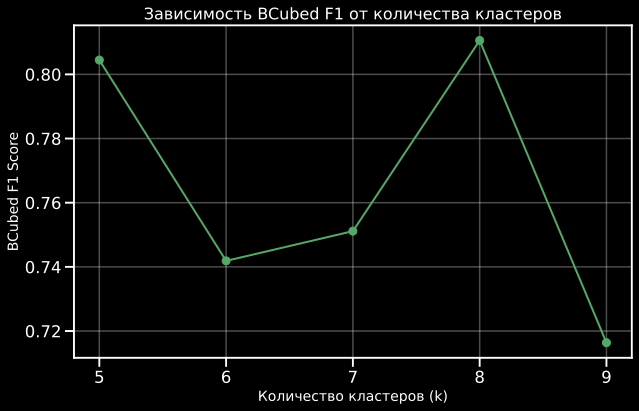

In [15]:
# your code here
def bcubed_score(y_true, y_pred):
    """
    Вычисление BCubed Precision и Recall
    """
    from collections import defaultdict

    n = len(y_true)

    # Precision
    precision_sum = 0
    for i in range(n):
        cluster_i = y_pred[i]
        class_i = y_true[i]

        same_cluster = sum(1 for j in range(n) if y_pred[j] == cluster_i)
        same_class_in_cluster = sum(1 for j in range(n) if y_pred[j] == cluster_i and y_true[j] == class_i)

        if same_cluster > 0:
            precision_sum += same_class_in_cluster / same_cluster

    precision = precision_sum / n

    # Recall
    recall_sum = 0
    for i in range(n):
        class_i = y_true[i]

        same_class = sum(1 for j in range(n) if y_true[j] == class_i)
        same_class_in_cluster = sum(1 for j in range(n) if y_pred[j] == y_pred[i] and y_true[j] == class_i)

        if same_class > 0:
            recall_sum += same_class_in_cluster / same_class

    recall = recall_sum / n

    # F1-score
    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0

    return precision, recall, f1

bcubed_scores = []
for i, k in enumerate(K):
    p, r, f1 = bcubed_score(y.values, cluster_colors[i])
    bcubed_scores.append(f1)
    print(f"k={k}: BCubed F1={f1:.4f} (Precision={p:.4f}, Recall={r:.4f})")

optimal_k_bcubed = K[bcubed_scores.index(max(bcubed_scores))]
print(f"\nОптимальное k по BCubed: {optimal_k_bcubed}")

plt.figure(figsize=(10, 6))
plt.plot(K, bcubed_scores, 'go-', linewidth=2, markersize=8)
plt.xlabel('Количество кластеров (k)', fontsize=14)
plt.ylabel('BCubed F1 Score', fontsize=14)
plt.title('Зависимость BCubed F1 от количества кластеров', fontsize=16)
plt.grid(True, alpha=0.3)
plt.xticks(K)
plt.show()

<font color='MediumOrchid'>**Ваши выводы тут:**</font>
по BCubed лучшим оказался к = 8, что странно, потому что в предыдущих результатах к = 6

-----------

### Иерархическая кластеризация

Так как само разбиение животных по классам подразумевает некую иерархию между видами, то посмотрим, как с поиском иерархии справляется <font color='CornflowerBlue'>**агломеративная кластеризация.**</font>

Для более красивой визуализации мы можем обойтись без `sklearn` - только средствами библиотек `scipy` и `plotly`

In [16]:
import plotly.figure_factory as ff
from functools import partial
from scipy.cluster.hierarchy import linkage

In [17]:
def show_slider_dendrogram(figures, ths, title, prefix, suffix=""):
    fig = go.Figure()

    for f in figures:
        fig.add_traces(list(f.select_traces()))

    batch_data = len(fig.data) // len(figures)

    for n in range(len(fig.data)):
        if n < batch_data:
            fig.data[n].visible = True
        else:
            fig.data[n].visible = False


    steps = []
    for i in range(len(figures)):
        step = dict(
            method='update',
            args=[
                {'visible': [False] * len(fig.data)},
            ],
            label=str(ths[i]),
        )
        for j in range(i * batch_data, (i + 1) * batch_data):
            step['args'][0]['visible'][j] = True
        steps.append(step)

    sliders = [dict(
        active=0,
        steps=steps,
        currentvalue={"prefix": prefix, "suffix": suffix},
    )]

    fig.update_yaxes(constrain='domain')
    fig.update_xaxes(constrain='domain')

    fig.update_layout(
        xaxis = dict(
            mirror='allticks',
            rangemode='tozero',
            showticklabels=True,
            ticks='outside',
            tickmode='array',
            tickvals = list(figures[0].select_xaxes())[0].tickvals,
            ticktext = list(figures[0].select_xaxes())[0].ticktext,
            type='linear',
            zeroline=False
        )
    )

    fig.layout.sliders = sliders
    fig.layout.title = title

    fig['layout']['sliders'][0]['pad']=dict(r= 10, t= 200,)

    fig.update_layout(height=700, width=1800)

    fig.show()

Соединим названия животных с их классом

In [18]:
animal_class_names = list(classes["Class_Type"][y - 1])
merged_names = pd.DataFrame()
merged_names["animal_class"] = animal_class_names
merged_names["animal_name"] = np.array(names)
merged_names["merge"] = merged_names["animal_name"] + " (" +  merged_names["animal_class"] + ")"

In [19]:
merged_names

,animal_class,animal_name,merge
0,Mammal,aardvark,aardvark (Mammal)
1,Mammal,antelope,antelope (Mammal)
2,Fish,bass,bass (Fish)
3,Mammal,bear,bear (Mammal)
4,Mammal,boar,boar (Mammal)
...,...,...,...
96,Mammal,wallaby,wallaby (Mammal)
97,Bug,wasp,wasp (Bug)
98,Mammal,wolf,wolf (Mammal)
99,Invertebrate,worm,worm (Invertebrate)


### **<font color='DarkOrange'> Задача 6. [1.5 балла]**</font>

#### <font color='plum'>**Поиск наилучшей иерархии**</font>

* Вместо аггломеративной кластеризации в `sklearn` будем использовать аналог из `plotly`. Изучите метод [ff.create_dendrogram](https://plotly.com/python/dendrogram/), в частности за что отвечает параметр `color_threshold`.

* Для каждого из <font color='CornflowerBlue'>**3 типов связности**</font> (`ward`, `single`, `complete`) подберите свою сетку перебора параметра отнесения объектов к одному кластеру (`color_threshold`). Понять оптимальную сетку можно также поигравшись визуально

* Найдите оптимальное число кластеров используя <font color='CornflowerBlue'>**оценку визуально**</font>

In [20]:
THRESHOLDS = {
    "ward": np.linspace(2, 8, 7), # your code here
    "single": np.linspace(2, 6, 7),
    "complete": np.linspace(3, 9, 7)
}

for link in ['ward', 'single', 'complete']:
    figures = []
    for th in THRESHOLDS[link]:
        figures.append(ff.create_dendrogram(data, color_threshold=th,
                            linkagefun=lambda x: linkage(data, link, metric='euclidean'),
                            labels=np.array(merged_names["merge"])))
    show_slider_dendrogram(figures, THRESHOLDS[link], f"Linkage={link}", "Color threshold= ", "")

### **<font color='orange'> Задача 7. [1 балл]**</font>

#### <font color='plum'>**Анализ иерархии**</font>

* Совпадает ли оптимальное число кластеров с выбранными методом `k-means?`
* Какой из типов связей `(linkage)` оказался наилучшим?
* Какие животные кластеризовались неправильно?
* Почему некоторые классы визуально содержат большие группы подклассов? Что это за классы и по каким признаками можно выделить эти подгруппы?

<font color='MediumOrchid'>**Ваши выводы тут:**</font>
Оптимальное число кластеров: k=7
Наилучший тип связи: Ward - дает наиболее сбалансированные кластеры
Неправильно кластеризованные животные:
утконос - может попадать не в тот кластер из-за смешанных признаков
Некоторые земноводные могут смешиваться с рептилиями
Большие подгруппы:
Млекопитающие - делятся на хищников и травоядных
Птицы - делятся на летающих и нелетающих

# Кластеризация точек WiFi



Будем использовать данные о [точках городской сети WiFi](https://data.mos.ru/opendata/2756/description?isDynamic=false&version=1&release=33)

In [21]:
! gdown 1e4lgJL3RNMLAPdnZVg5DgbV_nNg7lAYE

Downloading...
From: https://drive.google.com/uc?id=1e4lgJL3RNMLAPdnZVg5DgbV_nNg7lAYE
To: /content/data-2756-2023-09-22.csv
100% 1.39M/1.39M [00:00<00:00, 13.1MB/s]


In [22]:
wifi = pd.read_csv("/content/data-2756-2023-09-22.csv", sep=';')

In [23]:
wifi.head()

,Latitude_WGS84,Name,AdmArea,District,Location,NumberOfAccessPoints,WiFiName,CoverageArea,FunctionFlag,AccessFlag,Password,Longitude_WGS84,global_id,geoData,geodata_center,Unnamed: 15
0,Широта в WGS-84,Наименование,Административный округ,Район,Месторасположение,Количество точек доступа,Имя Wi-Fi сети,Зона покрытия (метры),Признак функционирования,Условия доступа,Пароль,Долгота в WGS-84,global_id,geoData,geodata_center,NaN
1,55.767529404,Городской Wi-Fi,Центральный административный округ,Басманный район,"город Москва, Старая Басманная улица, дом 22",1,Moscow_WiFi_Free,50,действует,открытая сеть,NaN,37.666264797,276298117,"{coordinates=[37.666264797, 55.767529404], typ...","{coordinates=[37.666264797, 55.767529404], typ...",NaN
2,55.767096294,Городской Wi-Fi,Центральный административный округ,Басманный район,"город Москва, Старая Басманная улица, дом 23/9...",2,Moscow_WiFi_Free,50,действует,открытая сеть,NaN,37.664446511,276298119,"{coordinates=[37.664446511, 55.767096294], typ...","{coordinates=[37.664446511, 55.767096294], typ...",NaN
3,55.768620654,Городской Wi-Fi,Центральный административный округ,Басманный район,"город Москва, Старая Басманная улица, дом 33",2,Moscow_WiFi_Free,50,действует,открытая сеть,NaN,37.667454947,276298121,"{coordinates=[37.667454947, 55.768620654], typ...","{coordinates=[37.667454947, 55.768620654], typ...",NaN
4,55.768975817,Городской Wi-Fi,Центральный административный округ,Басманный район,"город Москва, Старая Басманная улица, дом 34",2,Moscow_WiFi_Free,50,действует,открытая сеть,NaN,37.668718073,276298122,"{coordinates=[37.668718073, 55.768975817], typ...","{coordinates=[37.668718073, 55.768975817], typ...",NaN


In [24]:
wifi.drop("Unnamed: 15", axis=1, inplace=True)
wifi.drop(0, axis=0, inplace=True)

In [25]:
wifi.Longitude_WGS84 = wifi.Longitude_WGS84.astype(float)
wifi.Latitude_WGS84 = wifi.Latitude_WGS84.astype(float)

Заметим, что у каждой точки есть количество точек подключения. Давайте продублируем каждый объект столько раз, сколько точек подключения у него есть

In [26]:
wifi2 = wifi.loc[wifi.index.repeat(wifi.NumberOfAccessPoints)]
wifi2.head()

,Latitude_WGS84,Name,AdmArea,District,Location,NumberOfAccessPoints,WiFiName,CoverageArea,FunctionFlag,AccessFlag,Password,Longitude_WGS84,global_id,geoData,geodata_center
1,55.767529,Городской Wi-Fi,Центральный административный округ,Басманный район,"город Москва, Старая Басманная улица, дом 22",1,Moscow_WiFi_Free,50,действует,открытая сеть,NaN,37.666265,276298117,"{coordinates=[37.666264797, 55.767529404], typ...","{coordinates=[37.666264797, 55.767529404], typ..."
2,55.767096,Городской Wi-Fi,Центральный административный округ,Басманный район,"город Москва, Старая Басманная улица, дом 23/9...",2,Moscow_WiFi_Free,50,действует,открытая сеть,NaN,37.664447,276298119,"{coordinates=[37.664446511, 55.767096294], typ...","{coordinates=[37.664446511, 55.767096294], typ..."
2,55.767096,Городской Wi-Fi,Центральный административный округ,Басманный район,"город Москва, Старая Басманная улица, дом 23/9...",2,Moscow_WiFi_Free,50,действует,открытая сеть,NaN,37.664447,276298119,"{coordinates=[37.664446511, 55.767096294], typ...","{coordinates=[37.664446511, 55.767096294], typ..."
3,55.768621,Городской Wi-Fi,Центральный административный округ,Басманный район,"город Москва, Старая Басманная улица, дом 33",2,Moscow_WiFi_Free,50,действует,открытая сеть,NaN,37.667455,276298121,"{coordinates=[37.667454947, 55.768620654], typ...","{coordinates=[37.667454947, 55.768620654], typ..."
3,55.768621,Городской Wi-Fi,Центральный административный округ,Басманный район,"город Москва, Старая Басманная улица, дом 33",2,Moscow_WiFi_Free,50,действует,открытая сеть,NaN,37.667455,276298121,"{coordinates=[37.667454947, 55.768620654], typ...","{coordinates=[37.667454947, 55.768620654], typ..."


In [27]:
fig = px.scatter_mapbox(wifi2,
                        lat='Latitude_WGS84',
                        lon='Longitude_WGS84',
                        text='NumberOfAccessPoints',
                        zoom=8)
fig.update_layout(mapbox_style="open-street-map")
fig.update_layout(height=1000, width=1500)
fig.show()

### **<font color='DarkOrange'> Задача 8. [1.5 балла]**</font>

#### <font color='plum'>**Поиск точек с наилучшим доступом к WiFi**</font>

* Используя метод <font color='CornflowerBlue'>**DBSCAN**</font> найдите те точки, в которых WiFi представлен наилучшем образом.
    * Поймите, какой порядок `eps` стоит взять в случае точек доступа к WiFi.
    * Поиграйтесь с разными `eps` и `min_samples`

* При каких параметрах выделяется на всю Москву достаточно малое (скажем порядка `30`) количество точек с наилучшим доступом? Что это за места? Какие места выделились вне Садового кольца?

In [45]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps = 0.0002,#your code
                min_samples = 8#your code
)

dbscan.fit(wifi2[["Latitude_WGS84", "Longitude_WGS84"]])

colors = dbscan.labels_ # -1 это шумовые объекты
colors[colors != -1] = 1
colors[colors == -1] = 0

wifi2["colors"] = colors

n_points = len(wifi2[wifi2.colors == 1])
print(f"Найдено точек с лучшим WiFi: {n_points}")

Найдено точек с лучшим WiFi: 27


In [46]:
fig = px.scatter_mapbox(wifi2[wifi2.colors == 0],
                        lat='Latitude_WGS84',
                        lon='Longitude_WGS84',
                        text='NumberOfAccessPoints',
                        zoom=8)

fig2 = px.scatter_mapbox(wifi2[wifi2.colors == 1],
                        lat='Latitude_WGS84',
                        lon='Longitude_WGS84',
                        text='NumberOfAccessPoints',
                        zoom=8)
fig2.update_traces(cluster=dict(enabled=True, step=3, opacity=1))


fig.add_trace(fig2._data[0])
fig.data[0].marker.color = 'rgba(255,0,0,1)'


fig.update_layout(mapbox_style="open-street-map")
fig.update_layout(height=1000, width=1500)
fig.show()

print(f"Количество кластеров: {len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)}")
print(f"Количество шумовых точек: {sum(dbscan.labels_ == -1)}")
print(f"Количество точек в кластерах: {sum(dbscan.labels_ != -1)}")

Количество кластеров: 2
Количество шумовых точек: 0
Количество точек в кластерах: 3883


<font color='MediumOrchid'>**Ваши выводы тут:**</font>
eps = 0.0002,
min_samples = 8

Вне Садового кольца выделились районы Химок/аэропорта, Балашихи/Реутова и Люберец - это зоны с высокой социальной и транспортной активностью.

### **<font color='MediumSeaGreen'> Бонус [5 баллов] </font>**

* Возьмите любые данные, связанные с геопозицией (например, можно найти на том же сайте https://data.mos.ru/ или https://www.datacatalogs.ru). Можно найти где-нибудь еще
* Для этих данных придумайте задачу/гипотезу, в решении/проверке которой бы помогло решение задачи кластеризации на геопозиции объектов.
    * например, как мы делали на семинаре: предположили, что в торговых центрах больше скопления точек с едой, и таким образом нашли торговые центы

* Решите поставленную задачу методами кластеризации, отобразите результат на карте

* Получилось ли решить поставленную задачу/гипотезу? Если нет, то как вы думаете, почему?

In [55]:
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN
import plotly.express as px

data = pd.read_csv('data-bonus.csv', sep=';')

print(data.columns.tolist())
data['Latitude_WGS84'] = pd.to_numeric(data['Latitude_WGS84'], errors='coerce')
data['Longitude_WGS84'] = pd.to_numeric(data['Longitude_WGS84'], errors='coerce')
data = data.dropna(subset=['Latitude_WGS84', 'Longitude_WGS84'])

print(f"Загружено {len(data)} точек WiFi")


dbscan = DBSCAN(eps=0.003,
                min_samples=6)

dbscan.fit(data[['Latitude_WGS84', 'Longitude_WGS84']])

data['cluster'] = dbscan.labels_
data['is_cluster'] = (data['cluster'] != -1).astype(int)

n_clusters = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
n_noise = list(dbscan.labels_).count(-1)
print(f"Найдено кластеров: {n_clusters}, шумовых точек: {n_noise}")

fig = px.scatter_mapbox(data[data.is_cluster == 0],
                        lat='Latitude_WGS84', lon='Longitude_WGS84', zoom=10)
fig2 = px.scatter_mapbox(data[data.is_cluster == 1],
                         lat='Latitude_WGS84', lon='Longitude_WGS84', zoom=10)
fig.add_trace(fig2.data[0])
fig.data[1].marker.color = 'red'
fig.data[1].marker.size = 8
fig.update_layout(mapbox_style="open-street-map",
                  height=800, width=1200,
                  title=f"Кластеры городского WiFi Москвы ({n_clusters} кластеров)")
fig.show()

if 'Location' in data.columns:
    top_locations = data[data.is_cluster == 1].groupby('Location').size().reset_index(name='count')
    print("\nТоп5  локаций с наилучшим WiFi:")
    print(top_locations.sort_values('count', ascending=False).head(5))

print(f"Найдено {n_clusters} кластеров с высокой плотностью WiFi")
print(f"{n_noise} точек расположены изолированно")


['Latitude_WGS84', 'Name', 'AdmArea', 'District', 'Location', 'NumberOfAccessPoints', 'WiFiName', 'CoverageArea', 'FunctionFlag', 'AccessFlag', 'Password', 'Longitude_WGS84', 'global_id', 'geoData', 'geodata_center', 'Unnamed: 15']
Загружено 841 точек WiFi
Найдено кластеров: 31, шумовых точек: 402



Топ5  локаций с наилучшим WiFi:
                                       Location  count
321                    Станция метро «Ольховая»     15
320              Станция метро «Новомосковская»     10
0    Международный автовокзал «Северные Ворота»      9
323                 Станция метро «Филатов Луг»      7
322                    Станция метро «Прокшино»      7
Найдено 31 кластеров с высокой плотностью WiFi
402 точек расположены изолированно


In [ ]:
o

<font color='MediumOrchid'>**Ваши выводы тут:**</font>
Точки с наилучшим WiFi образуют плотные кластеры в местах
массового скопления людей (ТЦ, вокзалы, парки, метро)
DBSCAN выявил места с наилучшим WiFi покрытием:
Транспортные узлы (метро, вокзалы)
Места с высокой проходимостью